<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/58/Uber_logo_2018.svg/1024px-Uber_logo_2018.svg.png" alt="UBER LOGO" width="50%" />

# UBER Pickups 

## Company's Description 📇

<a href="http://uber.com/" target="_blank">Uber</a> is one of the most famous startup in the world. It started as a ride-sharing application for people who couldn't afford a taxi. Now, Uber expanded its activities to Food Delivery with <a href="https://www.ubereats.com/fr-en" target="_blank">Uber Eats</a>, package delivery, freight transportation and even urban transportation with <a href="https://www.uber.com/fr/en/ride/uber-bike/" target="_blank"> Jump Bike</a> and <a href="https://www.li.me/" target="_blank"> Lime </a> that the company funded. 


The company's goal is to revolutionize transportation accross the globe. It operates now on about 70 countries and 900 cities and generates over $14 billion revenue! 😮


## Project 🚧

One of the main pain point that Uber's team found is that sometimes drivers are not around when users need them. For example, a user might be in San Francisco's Financial District whereas Uber drivers are looking for customers in Castro.  

(If you are not familiar with the bay area, check out <a href="https://www.google.com/maps/place/San+Francisco,+CA,+USA/@37.7515389,-122.4567213,13.43z/data=!4m5!3m4!1s0x80859a6d00690021:0x4a501367f076adff!8m2!3d37.7749295!4d-122.4194155" target="_blank">Google Maps</a>)

Eventhough both neighborhood are not that far away, users would still have to wait 10 to 15 minutes before being picked-up, which is too long. Uber's research shows that users accept to wait 5-7 minutes, otherwise they would cancel their ride. 

Therefore, Uber's data team would like to work on a project where **their app would recommend hot-zones in major cities to be in at any given time of day.**  

## Goals 🎯

Uber already has data about pickups in major cities. Your objective is to create algorithms that will determine where are the hot-zones that drivers should be in. Therefore you will:

* Create an algorithm to find hot zones 
* Visualize results on a nice dashboard 

## Scope of this project 🖼️

To start off, Uber wants to try this feature in New York city. Therefore you will only focus on this city. Data can be found here: 

👉👉<a href="https://full-stack-bigdata-datasets.s3.eu-west-3.amazonaws.com/Machine+Learning+non+Supervis%C3%A9/Projects/uber-trip-data.zip" target="_blank"> Uber Trip Data</a> 👈👈

**You only need to focus on New York City for this project**

## Helpers 🦮

To help you achieve this project, here are a few tips that should help you: 

### Clustering is your friend 

Clustering technics are a perfect fit for the job. Think about it, all the pickup locations can be gathered into different clusters. You can then use **cluster coordinates to pin hot zones** 😉
    

### Create maps with `plotly` 

Check out <a href="https://plotly.com/" target="_blank">Plotly</a> documentation, you can create maps and populate them easily. Obviously, there are other libraries but this one should do the job pretty well. 


### Start small grow big 

Eventhough Uber wants to have hot-zones per hour and per day of week, you should first **start small**. Pick one day at a given hour and **then start to generalize** your approach. 

## Deliverable 📬

To complete this project, your team should: 

* Have a map with hot-zones using any python library (`plotly` or anything else). 
* You should **at least** describe hot-zones per day of week. 
* Compare results with **at least** two unsupervised algorithms like KMeans and DBScan. 

Your maps should look something like this: 

<img src="https://full-stack-assets.s3.eu-west-3.amazonaws.com/images/Clusters_uber_pickups.png" alt="Uber Cluster Map" />

In [2]:
# load data 

import pandas as pd
from pathlib import Path
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
dir_data = "./uber-trip-data"
taxi_zone_name = "taxi-zone-lookup.csv"
NYC_boroughs = ['Queens', 'Bronx', 'Manhattan', 'Staten Island', 'Brooklyn']


In [3]:

dir_data = "./uber-trip-data"

In [4]:
prefix = "uber-raw-data"
files_list = [p.name for p in Path(dir_data).glob(f"{prefix}*.csv")]

In [5]:
files_list =  sorted(files_list)
files_list

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-janjune-15.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [6]:
files_list2 =  files_list.copy()
files_list2.pop(2)
files_list2

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [7]:
files_list3 =  files_list.copy()
files_list3.remove("uber-raw-data-janjune-15.csv")
files_list3

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [8]:
files_list

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-janjune-15.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [9]:
uber_raw = pd.DataFrame()
dtype_list = {'Date/Time': str,'Lat': float,'Lon': float,
                                                      'Base': str}
for f in files_list3:
    df_raw = pd.read_csv(f"{dir_data}/{f}", dtype=dtype_list)
    print(len(df_raw))
    uber_raw = pd.concat([uber_raw,df_raw])
print(len(uber_raw))

564516
829275
796121
663844
652435
1028136
4534327


In [10]:
print(uber_raw.head())

          Date/Time      Lat      Lon    Base
0  4/1/2014 0:11:00  40.7690 -73.9549  B02512
1  4/1/2014 0:17:00  40.7267 -74.0345  B02512
2  4/1/2014 0:21:00  40.7316 -73.9873  B02512
3  4/1/2014 0:28:00  40.7588 -73.9776  B02512
4  4/1/2014 0:33:00  40.7594 -73.9722  B02512


In [11]:
uber_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 1028135
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


In [12]:
# read special file 2015 with different columns from the other files
filename2 = 'uber-raw-data-janjune-15.csv'
df_uber2 = pd.read_csv(f"{dir_data}/{filename2}")
df_uber2.head()

,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID
0,B02617,2015-05-17 09:47:00,B02617,141
1,B02617,2015-05-17 09:47:00,B02617,65
2,B02617,2015-05-17 09:47:00,B02617,100
3,B02617,2015-05-17 09:47:00,B02774,80
4,B02617,2015-05-17 09:47:00,B02617,90


In [13]:
#will not be used immediately as no coordinates are identified, to be joined with taxi_zone :

In [14]:
# taxi_zone : 
taxi_zone_df = pd.read_csv(f"{dir_data}/{taxi_zone_name}")

taxi_zone_df.head()

,LocationID,Borough,Zone
0,1,EWR,Newark Airport
1,2,Queens,Jamaica Bay
2,3,Bronx,Allerton/Pelham Gardens
3,4,Manhattan,Alphabet City
4,5,Staten Island,Arden Heights


In [15]:
borough_list = taxi_zone_df["Borough"].unique()
borough_list

array(['EWR', 'Queens', 'Bronx', 'Manhattan', 'Staten Island', 'Brooklyn',
       'Unknown'], dtype=object)

In [16]:
# one single file:
file = "uber-raw-data-apr14.csv"

In [17]:
df1_day_filt2 = pd.read_csv(f"{dir_data}/{file}")
df1_day_filt2.head()

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512


In [18]:
df1_day_filt2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  object 
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  object 
dtypes: float64(2), object(2)
memory usage: 17.2+ MB


In [19]:
def uber_raw_formating(df):
    # survey of dates : 
    df["Date/Time"] = pd.to_datetime(df["Date/Time"], format="%m/%d/%Y %H:%M:%S", 
                                    errors="coerce")

    # Contrôle des dates non parsées
    n_invalides = df["Date/Time"].isna().sum()
    if n_invalides:
        print(f"Attention : {n_invalides} dates invalides (NaT)")

    # Extraction des composantes
    dt = df["Date/Time"].dt
    df["day"] = dt.day
    df["hour"] = dt.hour
    df["weekday"] = dt.weekday  # 0 = lundi
    df["month"] = dt.month
    return df

df_raw = uber_raw_formating(uber_raw)
df_raw.head()


,Date/Time,Lat,Lon,Base,day,hour,weekday,month
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,1,0,1,4
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,1,0,1,4
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,1,0,1,4
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,1,0,1,4
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,1,0,1,4


In [20]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 1028135
Data columns (total 8 columns):
 #   Column     Dtype         
---  ------     -----         
 0   Date/Time  datetime64[ns]
 1   Lat        float64       
 2   Lon        float64       
 3   Base       object        
 4   day        int32         
 5   hour       int32         
 6   weekday    int32         
 7   month      int32         
dtypes: datetime64[ns](1), float64(2), int32(4), object(1)
memory usage: 242.2+ MB


In [21]:
print(f"days : {df_raw['day'].unique()}")
print(f"months : {df_raw['month'].unique()}")
print(f"years : {df_raw['Date/Time'].dt.year.unique()}")

days : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]
months : [4 8 7 6 5 9]
years : [2014]


In [22]:
# pick one day and one hour : 
df1 = df_raw[(df_raw['month']==4)].copy()  # all days of april 2014

# let's filter only day 7 of month 4 (april) and hour 8 (8am)
df1_filtered = df_raw[(df_raw['day'] == 7) & (df_raw['month']==4) & (df_raw['hour'] == 8)].copy()
df1_filtered

,Date/Time,Lat,Lon,Base,day,hour,weekday,month
7947,2014-04-07 08:00:00,40.7205,-73.9968,B02512,7,8,0,4
7948,2014-04-07 08:01:00,40.7747,-73.9901,B02512,7,8,0,4
7949,2014-04-07 08:01:00,40.7741,-73.8723,B02512,7,8,0,4
7950,2014-04-07 08:02:00,40.7354,-74.0039,B02512,7,8,0,4
7951,2014-04-07 08:04:00,40.7307,-73.9852,B02512,7,8,0,4
...,...,...,...,...,...,...,...,...
556772,2014-04-07 08:23:00,40.7664,-73.9671,B02764,7,8,0,4
556773,2014-04-07 08:38:00,40.7245,-73.9986,B02764,7,8,0,4
556774,2014-04-07 08:42:00,40.7799,-73.9446,B02764,7,8,0,4
556775,2014-04-07 08:50:00,40.7503,-73.9945,B02764,7,8,0,4


In [23]:
df1.sample(8)

,Date/Time,Lat,Lon,Base,day,hour,weekday,month
212427,2014-04-30 16:42:00,40.7645,-73.9706,B02598,30,16,2,4
341953,2014-04-03 08:12:00,40.7420,-73.9779,B02682,3,8,3,4
125691,2014-04-18 00:38:00,40.7214,-73.9973,B02598,18,0,4,4
61415,2014-04-05 22:54:00,40.7328,-73.9960,B02598,5,22,5,4
462459,2014-04-18 20:19:00,40.7218,-73.9875,B02682,18,20,4,4
548543,2014-04-30 17:02:00,40.6786,-73.9413,B02682,30,17,2,4
123438,2014-04-17 19:15:00,40.7678,-73.9324,B02598,17,19,3,4
495204,2014-04-24 07:52:00,40.7534,-73.9865,B02682,24,7,3,4


In [24]:
len(df1_filtered)

836

In [25]:
comment = (
    "Base location have no special correlation with pickup locations, \n"
    "as the Base is only the dispatching center for the drivers, \n"
    "and not the pickup location of the passengers"
)
comment.splitlines()

['Base location have no special correlation with pickup locations, ',
 'as the Base is only the dispatching center for the drivers, ',
 'and not the pickup location of the passengers']

In [26]:
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)

In [27]:
html

'Base location have no special correlation with pickup locations, <br>as the Base is only the dispatching center for the drivers, <br>and not the pickup location of the passengers'

In [28]:
# plot sub set 1hour : 


fig=px.scatter_map(df1_filtered, lat='Lat',lon='Lon',
                   color = "Base", height = 700, 
                   zoom=10,
                   title = "Uber pickups in NYC per Base for day 7 of april 2014, hour 8am",
                   )
comment = (
    "Base location have no special correlation with pickup locations, \n"
    "as the Base is only the dispatching center for the drivers, \n "
    "and not the pickup location of the passengers"
)
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)
#print(html)

fig.add_annotation(
    xref = "paper", yref = "paper", 
    x=0.45, y=-0.1, 
    text=html,
    showarrow=False,
    font=dict(size=12, color="black")
)
fig.show()

In [29]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17
df1 = df_raw[(df_raw['month']==4)].copy()  # all days of april 2014
df1_day = df1[(df1['day'] == 7) & (df1['month']==4) ]

df1fil_8 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 8)]
df1fil_11= df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 11)]
df1fil_13 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 13)]
df1fil_17 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 17)]


In [30]:
# stratify data by day of week and 1 hour of the day, to see if there is a difference in the pickup locations
df_raw['schedule'] = df_raw['weekday'].astype(str) + "_" + df_raw['hour'].astype(str)

In [31]:
# Let's now add information abou NYC boroughs to add information, 
# and then filter out points outside NYC boroughs (outliers) and points outside the bounding box of NYC

# 1.compute utm coordinates (meters coordinates) for the filtered data frame
import utm
# utm.from_latlon(latitude, longitude)
def latlon_to_utm(df):
    df1 = df.copy() 
    df1[['easting', 'northing', 'zone_number', 'zone_letter']] = df1.apply(
        lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
        axis=1, 
        result_type='expand'
    )
    # limit precision of easting & northing to one meter, no decomals
    df1['easting'] = df1['easting'].round(0).astype(int)
    df1['northing'] = df1['northing'].round(0).astype(int)
    return df1



# 2. Identification of points per borough for filtering out of NYC points (outliers)

import numpy as np
import pandas as pd
import geopandas as gpd


def ajouter_borough(df, chemin_shp, lat="lat", lon="lon",
                    col_nom="BoroName", col_sortie="borough",
                    hors_zone=None):
    """Ajoute la colonne `col_sortie` (nom du borough) à df via jointure spatiale.

    - df : DataFrame avec colonnes lat/lon (WGS84, degrés)
    - hors_zone : valeur pour les points hors NYC ou à coordonnées invalides
    """
    # --- Chargement des polygones
    boroughs = gpd.read_file(chemin_shp)
    if col_nom not in boroughs.columns:
        raise KeyError(f"Colonne '{col_nom}' absente. Colonnes dispo : {list(boroughs.columns)}")
    if boroughs.crs is None:
        raise ValueError("Le shapefile n'a pas de CRS défini (.prj manquant ?).")
    boroughs = boroughs[[col_nom, "geometry"]]

    # --- Coordonnées valides uniquement
    la = pd.to_numeric(df[lat], errors="coerce")
    lo = pd.to_numeric(df[lon], errors="coerce")
    valide = la.between(-90, 90) & lo.between(-180, 180)

    # --- Points en WGS84 puis reprojection dans le CRS des polygones
    pts = gpd.GeoDataFrame(
        index=df.index[valide],
        geometry=gpd.points_from_xy(lo[valide], la[valide]),
        crs="EPSG:4326",
    ).to_crs(boroughs.crs)

    # --- Jointure spatiale (une seule opération vectorisée)
    jointure = gpd.sjoin(pts, boroughs, how="left", predicate="within")
    # Points sur une frontière : on garde le premier match
    jointure = jointure[~jointure.index.duplicated(keep="first")]

    # --- Réinjection alignée sur l'index de df
    df = df.copy()
    df[col_sortie] = hors_zone
    df.loc[jointure.index, col_sortie] = jointure[col_nom].where(
        jointure[col_nom].notna(), hors_zone
    )
    return df


In [32]:

# add utm coordinates:
df_raw = latlon_to_utm(df_raw)

#Add Borough: 
# print(df["borough"].value_counts(dropna=False))
path_nyc_borough_zip = "zip://C:/Users/Cyril/Documents/python/jedha/jedha_Full_stack/Jedha_certif_CDSD/Block3/Uber/Bl3_Uber_cyril/nybbwi_26c.zip"
path_nyc_borough = "C:/Users/Cyril/Documents/python/jedha/jedha_Full_stack/Jedha_certif_CDSD/Block3/Uber/Bl3_Uber_cyril/nybbwi_26c/nybbwi.shp"

df_raw = ajouter_borough(df_raw, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")

print(df_raw["borough"].value_counts(dropna=False))


borough
Manhattan        3528720
Brooklyn          561418
Queens            300677
Hors NYC          112619
Bronx              29884
Staten Island       1009
Name: count, dtype: int64


In [33]:
df_raw.head()

,Date/Time,Lat,Lon,Base,day,hour,weekday,month,schedule,easting,northing,zone_number,zone_letter,borough
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,1,0,1,4,1_0,588201,4513640,18,T,Manhattan
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,1,0,1,4,1_0,581535,4508867,18,T,Hors NYC
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,1,0,1,4,1_0,585515,4509456,18,T,Manhattan
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,1,0,1,4,1_0,586299,4512485,18,T,Manhattan
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,1,0,1,4,1_0,586754,4512557,18,T,Manhattan


In [34]:

# select only NYC boroughs and points in the bounding box of NYC
NYC_borough = ["Manhattan","Brooklyn","Queens","Bronx","Staten Island"]

df_rawb = df_raw[df_raw["borough"].isin(NYC_borough)].copy()
    
def filter_nyc_boroughs(df):
    df_filtered = df[ (df["borough"].isin(NYC_borough)) |
        ((df["borough"] =='Hors NYC') & 
        (df['Lat'] < 40.93) & 
        (df['Lon'] > -74.076) & 
        (df['Lon'] < -73.66))].copy()
    return df_filtered 

# or do it with df1_day if too long !
df_rawb = filter_nyc_boroughs(df_raw)
df1_day = df_rawb[(df_rawb['day'] == 7) & (df_rawb['month']==4) ]
#df1_day = filter_nyc_boroughs(df1_day)

print(f"Value counts for df_rawb:\n{df_rawb['borough'].value_counts(dropna=False)}")

# plot sub set 1hour : 
fig=px.scatter_map(df1_2mth, lat='Lat',lon='Lon',
                   color = "borough", height = 700,
                   title = "Uber pickups in NYC boroughs for day 7 of april 2014")
comment = (
    "NYC boroughs added to points identification, \n"
    "better to understand hot areas, \n "
    )
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)
#print(html)

fig.add_annotation(
    xref = "paper", yref = "paper", 
    x=0.45, y=-0.1, 
    text=html,
    showarrow=False,
    font=dict(size=12, color="black")
)
fig.show()

Value counts for df_rawb:
borough
Manhattan        3528720
Brooklyn          561418
Queens            300677
Hors NYC           97132
Bronx              29884
Staten Island       1009
Name: count, dtype: int64


NameError: name 'df1_2mth' is not defined

In [ ]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17
df1 = df_rawb[(df_rawb['month']==4)].copy()  # all days of april 2014
df1_day = df1[(df1['day'] == 7) & (df1['month']==4) ]

df1fil_8 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 8)]
df1fil_11= df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 11)]
df1fil_13 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 13)]
df1fil_17 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 17)]




In [ ]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17 

df1_day["dateframe"] = df1_day["Date/Time"].dt.floor('10min')
df1_day.sample(10)

C:\Users\Cyril\AppData\Local\Temp\ipykernel_32056\3924562136.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Date/Time,Lat,Lon,Base,day,hour,weekday,month,easting,northing,zone_number,zone_letter,borough,schedule,dateframe
8753,2014-04-07 18:43:00,40.7618,-73.9879,B02512,7,18,0,4,585426,4512808,18,T,Manhattan,0_18,2014-04-07 18:40:00
243271,2014-04-07 14:37:00,40.7202,-73.9969,B02617,7,14,0,4,584719,4508181,18,T,Manhattan,0_14,2014-04-07 14:30:00
383623,2014-04-07 20:57:00,40.7519,-73.9797,B02682,7,20,0,4,586130,4511717,18,T,Manhattan,0_20,2014-04-07 20:50:00
7877,2014-04-07 06:50:00,40.7707,-73.9476,B02512,7,6,0,4,588815,4513836,18,T,Manhattan,0_6,2014-04-07 06:50:00
382908,2014-04-07 19:44:00,40.7582,-73.9901,B02682,7,19,0,4,585244,4512406,18,T,Manhattan,0_19,2014-04-07 19:40:00
380908,2014-04-07 17:36:00,40.7565,-73.9701,B02682,7,17,0,4,586935,4512237,18,T,Manhattan,0_17,2014-04-07 17:30:00
380801,2014-04-07 17:29:00,40.7325,-73.9969,B02682,7,17,0,4,584703,4509547,18,T,Manhattan,0_17,2014-04-07 17:20:00
8841,2014-04-07 19:14:00,40.7366,-73.9950,B02512,7,19,0,4,584858,4510004,18,T,Manhattan,0_19,2014-04-07 19:10:00
242062,2014-04-07 06:07:00,40.7388,-74.0059,B02617,7,6,0,4,583935,4510237,18,T,Manhattan,0_6,2014-04-07 06:00:00
67006,2014-04-07 09:55:00,40.7236,-74.0014,B02598,7,9,0,4,584334,4508554,18,T,Manhattan,0_9,2014-04-07 09:50:00


In [ ]:
df1_2mth = df_rawb[(df_rawb['month'].isin([4,5]))].copy()  # all days of april and may 2014
df_1m = df_rawb[(df_rawb['month'].isin([4,5]))]
len(df1_2mth)

NameError: name 'df_rawb' is not defined

In [ ]:
#view data bargraph of pickups per weekday & hour and coloured per borough, to see if there is a difference in the pickup locations
# for weekday = 0 to 6:
# plot bargraph of nb pickup vs hour in subplots on 2 lines & 4 columns 
#from matplotlib.pyplot import subplots
from plotly.subplots import make_subplots


fig = make_subplots(rows=2, cols=4, shared_xaxes=True, vertical_spacing=0.05, horizontal_spacing=0.05)
for day in range(7):
    fig.add_trace(
        go.Histogram(data = df_1m, x='hour',y=count ,
               row= (day) // 4 + 1 ,col = (day) % 4 + 1 )
    )
         
    

In [ ]:
fig=px.scatter_map(df1_2mth, 
                   lat='Lat',lon='Lon',
                   color = "borough",
                   animation_frame = 'schedule', height = 800,
                   zoom=10,
                   title = "Uber pickups in NYC boroughs for day 7 of april 2014, animated by 10min time frame")
fig.show()

In [ ]:
bases_raw = uber_raw["Base"].unique()
bases_raw

array(['B02512', 'B02598', 'B02617', 'B02682', 'B02764'], dtype=object)

In [ ]:
len(uber_raw)

4534327

In [ ]:
!dir


 Le volume dans le lecteur C s'appelle OS
 Le num�ro de s�rie du volume est 64CF-2E6C

 R�pertoire de c:\Users\Cyril\Documents\python\jedha\jedha_Full_stack\Jedha_certif_CDSD\Block3\Uber\Bl3_Uber_cyril

08/10/2026  16:15    <DIR>          .
08/10/2026  16:09    <DIR>          ..
09/10/2026  16:33                99 .gitignore
12/10/2026  15:37         1�822�214 01-Uber_Pickups_cyril.ipynb
08/10/2026  16:16    <DIR>          nybbwi_26c
08/10/2026  16:06            34�916 nybbwi_26c.zip
06/10/2026  15:38    <DIR>          uber-trip-data
               3 fichier(s)        1�857�229 octets
               4 R�p(s)  272�713�461�760 octets libres


In [ ]:


# utm.from_latlon(latitude, longitude)
easting, northing, zone_number, zone_letter = utm.from_latlon(40.7560 ,-73.9761)
print(easting, northing, zone_number, zone_letter)

586429.0225352568 4512175.513962113 18 T


In [ ]:
# utm.from_latlon(latitude, longitude) extreme west @ newark 
easting, northing, zone_number, zone_letter = utm.from_latlon(40.8172 ,-74.2591)
print(easting, northing, zone_number, zone_letter)

562482.9161834557 4518728.924361323 18 T


In [ ]:
easting, northing, zone_number, zone_letter = utm.from_latlon(41.8902, 12.4924)
print(easting, northing, zone_number, zone_letter)

291962.587877766 4640626.112070618 33 T


In [ ]:
df1fil_17.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2184 entries, 8472 to 556928
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date/Time    2184 non-null   datetime64[ns]
 1   Lat          2184 non-null   float64       
 2   Lon          2184 non-null   float64       
 3   Base         2184 non-null   object        
 4   day          2184 non-null   int32         
 5   hour         2184 non-null   int32         
 6   weekday      2184 non-null   int32         
 7   month        2184 non-null   int32         
 8   easting      2184 non-null   int64         
 9   northing     2184 non-null   int64         
 10  zone_number  2184 non-null   int64         
 11  zone_letter  2184 non-null   object        
 12  borough      2184 non-null   object        
dtypes: datetime64[ns](1), float64(2), int32(4), int64(3), object(3)
memory usage: 204.8+ KB


In [ ]:
df1fil_8.info()

<class 'pandas.core.frame.DataFrame'>
Index: 824 entries, 7947 to 556776
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date/Time    824 non-null    datetime64[ns]
 1   Lat          824 non-null    float64       
 2   Lon          824 non-null    float64       
 3   Base         824 non-null    object        
 4   day          824 non-null    int32         
 5   hour         824 non-null    int32         
 6   weekday      824 non-null    int32         
 7   month        824 non-null    int32         
 8   easting      824 non-null    int64         
 9   northing     824 non-null    int64         
 10  zone_number  824 non-null    int64         
 11  zone_letter  824 non-null    object        
 12  borough      824 non-null    object        
dtypes: datetime64[ns](1), float64(2), int32(4), int64(3), object(3)
memory usage: 77.2+ KB


In [ ]:
df1fil_8.zone_letter.unique()

array(['T'], dtype=object)

# determine hotpoints for a short period : EG 7/apris 2014 between 8-9 AM : or 17-18 PM

In [ ]:
# ============================Clusters analysis ====================================
df = df1fil_17.copy()
df[['easting', 'northing', 'zone_number', 'zone_letter']] = df.apply(
    lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
    axis=1, 
    result_type='expand'
)
X0 = df[["Lat", "Lon"]].values
X3 = df[['northing','easting']].values  # coordinates in meters !! 
from sklearn.preprocessing import StandardScaler
# Initialize StandardScaler
# StandardScaler will substract mean and divide by standard deviation to each observation
sc = StandardScaler()
# Apply StandardScaler to X
X = sc.fit_transform(X0)

In [ ]:
X3

array([[4511912.84574364,  586752.91166527],
       [4511917.73768574,  586220.96185372],
       [4514291.96198063,  595148.40326717],
       ...,
       [4512759.86933323,  587030.01292489],
       [4512342.91194268,  586503.04962436],
       [4511788.1706374 ,  586534.85643686]], shape=(2184, 2))

In [ ]:
# first test with dbscan :

from sklearn.cluster import KMeans, DBSCAN
import numpy as np

coords = np.radians(X0) 

# use Haversine distance : 
# 6371 est le rayon de la Terre en km. eps = 1.5 km ici.
kms_per_radian = 6371.0
epsilon = 1.7 / kms_per_radian

db = DBSCAN(eps=0.35, min_samples=100, metric="manhattan", algorithm="ball_tree")
db2 = DBSCAN(eps=epsilon, min_samples=50, metric="haversine", algorithm="ball_tree")
db3 = DBSCAN(eps=400, min_samples=5, metric="manhattan", algorithm="ball_tree")
db4 = DBSCAN(eps=800, min_samples=5, metric="manhattan", algorithm="ball_tree")
# Fit on data
## No need to normalize data, it already is!
# with normalised data !
db.fit(X)

labels2 = db2.fit_predict(coords)
labels3 = db3.fit_predict(X3)
labels4 = db4.fit_predict(X3)
# Visualize with plotly

## Import go to build our own figure
import plotly.graph_objects as go


#df1fil_8['cluster'] = db.labels_
df['cluster'] = db.labels_ 
df['cluster2'] = labels2
df['cluster3'] = labels3
df['cluster4'] = labels4
cluster_comments = [
    "DBSCAN with Manhattan distance on Lat Lon, eps=0.35 (deg ?), min_samples=100",
    "DBSCAN with Haversine distance on Lat Lon, eps=1.7 (km ?), min_samples=50",
    "DBSCAN with Manhattan distance on utm coords, eps=400 (meters), min_samples=10",
    "DBSCAN with Manhattan distance on utm coords, eps=800 (meters), min_samples=10"
]


# shall compute max distance between center of each cluster and points of cluster:

In [ ]:
# Cluster centers coordinates

from scipy.spatial.distance import cdist

def centres_clusters(df, cluster_col, methode="medoide",
                     critere="somme", metric="cityblock"):
    """Calcule le centre et le rayon de chaque cluster (bruit -1 ignoré).

    - labels : labels DBSCAN (n,)
    - coords : array (n, d), requis pour 'centroide' ou si D est absent
    - D : matrice de distances précalculée (n, n), ex. distances routières
    - methode : 'centroide' ou 'medoide'
    - critere : 'somme' (médoïde classique) ou 'max' (minimax, rayon minimal)
    - metric : distance utilisée si D est absent (ex. 'cityblock', 'euclidean')
    Retourne un DataFrame : cluster, n_points, idx_centre, centre, rayon_max
    """
    df2 = df.copy()
    df2 = df2[df2[cluster_col] != -1].copy()
    labels = df2[cluster_col].values
    coords = df2[['easting','northing']].values
    
    zone_number = df2['zone_number'].values[0]
    zone_letter = df2['zone_letter'].values[0]
    #labels = np.asarray(labels)
    coords = None if coords is None else np.asarray(coords, dtype=float)
    if metric not in ("cityblock", "euclidean"):
            raise ValueError("metric doit être 'cityblock' ou 'euclidean'.")
        
    D = cdist(coords, coords, metric=metric)
    D = None if D is None else np.asarray(D, dtype=float)

    # Vérifications
    if methode not in ("centroide", "medoide"):
        raise ValueError("methode doit être 'centroide' ou 'medoide'.")
    if critere not in ("somme", "max"):
        raise ValueError("critere doit être 'somme' ou 'max'.")
    if coords is None and (D is None or methode == "centroide"):
        raise ValueError("coords est requis (centroïde, ou médoïde sans matrice D).")
    n = len(labels)
    if (coords is not None and len(coords) != n) or (D is not None and D.shape != (n, n)):
        raise ValueError("Tailles incohérentes entre labels, coords et D.")

    lignes = []
    for k in np.unique(labels[labels >= 0]):          # exclut le bruit (-1)
        idx = np.where(labels == k)[0]

        if methode == "centroide":
            c = coords[idx].mean(axis=0)
            rayon = cdist(coords[idx], c[None, :], metric=metric).max()
            lignes.append((k, len(idx), None, tuple(c), rayon))
            continue

        # Médoïde / minimax : sous-matrice des distances intra-cluster
        sub = D[np.ix_(idx, idx)] if D is not None else cdist(coords[idx], coords[idx], metric=metric)
        score = sub.sum(axis=1) if critere == "somme" else sub.max(axis=1)
        j = int(np.argmin(score))
        centre = tuple(coords[idx[j]]) if coords is not None else None
        lignes.append((k, len(idx), int(idx[j]), centre, sub[j].max()))
        

    centres_df = pd.DataFrame(lignes, columns=["cluster", "n_points", "idx_centre", "centre", "rayon_max"])
    centres_df[['Lat', 'Lon']] = centres_df.apply(
        lambda row: utm.to_latlon(row["centre"][0], row["centre"][1],
                                  zone_number, zone_letter),
        axis=1,
        result_type='expand')  
        
    
    # df1[['easting', 'northing', 'zone_number', 'zone_letter']] = df1.apply(
    #         lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
    #         axis=1, 
    #         result_type='expand'
    #     )
    
    return centres_df

# Exemple avec Manhattan sur des coordonnées projetées (mètres)



In [ ]:
import plotly.graph_objects as go


cluster_col='cluster3'
centres = centres_clusters(df, cluster_col, methode="medoide", critere="max")
print(centres)

    

fig=px.scatter_map(df, lat='Lat',lon='Lon',
                   color = df[cluster_col].astype(str),
                   hover_data={'easting','northing','borough' },
                   zoom = 10,
                   height=750,
                   title= cluster_comments[3])
fig_centers = px.scatter_map(
    centres,
    lat=centres['Lat'],  # northing
    lon=centres['Lon'],  # easting
    color='cluster',
    hover_data = {'centre': 'centre',
                  'Lat':'Lat','Lon':'Lon','n_points':'n_points','rayon_max':'rayon_max'},
    #symbol='cluster',
    #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
)
# Agrandir les croix
fig_centers.update_traces(marker_size=20)
# Ajouter toutes les traces des centroïdes
for trace in fig_centers.data:
    fig.add_trace(trace)

fig.show()


    cluster  n_points  idx_centre                                  centre  \
0         0      1919        1653  (585646.8333094342, 4511189.434089646)   
1         1         9        1116  (595140.2495614367, 4514269.651850297)   
2         2        17          50  (602950.8209789221, 4500051.408459877)   
3         3         8         936  (584715.7558383971, 4512866.262346677)   
4         4         7         791  (602310.0418026064, 4499909.331935699)   
5         5        13        1707  (586251.7036097703, 4509275.767493353)   
6         6        18         977  (585617.7594211361, 4506392.964674558)   
7         7        11         332   (587887.405183785, 4508084.830795843)   
8         8         5         367   (603431.0815900328, 4500180.20370863)   
9         9         5         520  (587625.7878402107, 4507348.988683239)   
10       10        12        1773  (585908.7439598289, 4505341.626054313)   
11       11         5        1557   (589293.955016658, 4511232.487317435)   

# comment about DBSCAN :
DBSCAN does not work when goal is to extract clusters with specfic max diameter ... 

In [ ]:
# use of AgglomerativeClustering


import numpy as np
from sklearn.cluster import AgglomerativeClustering


def clusters_diametre_max(df, seuil,  linkage="complete"):
    """Regroupe des points tels que la distance max intra-cluster <= seuil.

    - df : DataFrame avec colonnes 'easting' et 'northing' (coordonnées projetées UTM)
    - matrice_dist : array (n, n) symétrique, diagonale nulle (ex. durées/distances OSRM)
    - seuil : même unité que la matrice (mètres if easting & northing are in meters )
    - retourne : labels (n,) entiers : la colonne des clusters
    """
    
    coords = df[['easting','northing']].values   #coordinates in meters !!
        
    
    coords = None if coords is None else np.asarray(coords, dtype=float)
            
    D = cdist(coords, coords, metric="cityblock")
    D = None if D is None else np.asarray(D, dtype=float)
    
    # Vérifications de base
    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("La matrice des distances doit être carrée (n, n).")
    if not np.isfinite(D).all():
        raise ValueError("NaN/inf détectés (points non joignables par la route ?).")
    if linkage == "ward":
        raise ValueError("'ward' est incompatible avec une matrice précalculée.")
    if len(D) < 2:
        return np.zeros(len(D), dtype=int)

    # Les distances routières sont souvent asymétriques (sens uniques) : on symétrise
    D = np.maximum(D, D.T)
    np.fill_diagonal(D, 0)

    modele = AgglomerativeClustering(
        n_clusters=None,              # obligatoire avec distance_threshold
        metric="precomputed",         # sklearn >= 1.2 (sinon affinity=...)
        linkage=linkage,
        distance_threshold=seuil,
    )
    return modele.fit_predict(D)



In [ ]:

# Exemple rapide avec la distance de Manhattan sur des coordonnées projetées (mètres)
from scipy.spatial.distance import cdist

df['cluster_diam_max'] = clusters_diametre_max(df, seuil=3400)

labels = df['cluster_diam_max']
print("Nb clusters :", labels.nunique())


Nb clusters : 44


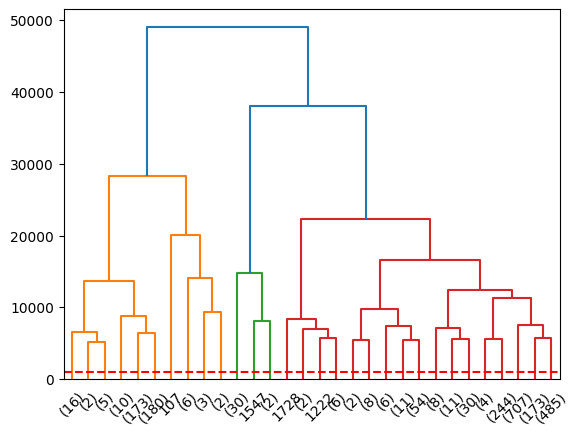

In [ ]:
from scipy.cluster.hierarchy import linkage as sp_linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
xy = df[['easting','northing']].values
D = cdist(xy, xy, metric="cityblock")
Z = sp_linkage(squareform(D, checks=False), method="complete")
dendrogram(Z, truncate_mode="lastp", p=30)
plt.axhline(1000, color="r", ls="--")  # ton seuil
plt.show()

In [ ]:

cluster_col = 'cluster_diam_max'
cluster_comment2 = (
    "AgglomerativeClustering with Manhattan distance on utm coords, distance_threshold=1700 (meters), linkage='complete'"
)
fig=px.scatter_map(df, lat='Lat',lon='Lon',
                   color = df[cluster_col].astype(str),
                   hover_data={'easting','northing','borough' },
                   zoom = 10,
                   height=750,
                   title= cluster_comment2)
# fig_centers = px.scatter_map(
#     centres,
#     lat=centres['Lat'],  # northing
#     lon=centres['Lon'],  # easting
#     color='cluster',
#     hover_data = {'centre': 'centre',
#                   'Lat':'Lat','Lon':'Lon','n_points':'n_points','rayon_max':'rayon_max'},
#     #symbol='cluster',
#     #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
# )
# # Agrandir les croix
# fig_centers.update_traces(marker_size=20)
# # Ajouter toutes les traces des centroïdes
# for trace in fig_centers.data:
#     fig.add_trace(trace)

fig.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def kcenter_glouton(df, k=None, rayon=None, metric="cityblock",
                    cols=("easting", "northing"), D=None, premier=None):
    """k-center glouton (Gonzalez, farthest-first) : chaque point est à <= rayon de son centre.

    - k : nombre de centres voulu (optionnel)
    - rayon : rayon max (m) ; on ajoute des centres jusqu'à ce qu'il soit respecté (optionnel)
      -> au moins un des deux est requis ; si les deux sont donnés, on s'arrête au premier atteint
    - metric : 'cityblock' (Manhattan) ou 'euclidean', sur les colonnes `cols` (mètres)
    - D : matrice (n, n) de distances précalculées (ex. OSRM), remplace `metric`
    - premier : position (iloc) du 1er centre ; défaut : point le plus proche du barycentre
      (résultat déterministe)
    Retourne (labels : array (n,), centres : DataFrame cluster, idx_centre, n_points, rayon_max, cols...)
    """
    # --- Vérifications ---
    if k is None and rayon is None:
        raise ValueError("Donne k, rayon, ou les deux.")
    if k is not None and (int(k) != k or k < 1):
        raise ValueError("k doit être un entier >= 1.")
    if rayon is not None and rayon < 0:
        raise ValueError("rayon doit être >= 0.")
    if metric not in ("cityblock", "euclidean"):
        raise ValueError("metric doit être 'cityblock' ou 'euclidean'.")
    if any(c not in df.columns for c in cols):
        raise KeyError(f"Colonnes manquantes : {cols}")

    coords = df[list(cols)].to_numpy(dtype=float)
    n = len(coords)
    if n == 0:
        raise ValueError("DataFrame vide.")
    if not np.isfinite(coords).all():
        raise ValueError("NaN/inf dans les coordonnées.")
    if D is not None:
        D = np.asarray(D, dtype=float)
        if D.shape != (n, n):
            raise ValueError(f"D doit être de forme ({n}, {n}).")

    # Distances de tous les points vers le point i : O(n) mémoire, pas de matrice n x n
    def dist(i):
        return D[i] if D is not None else cdist(coords, coords[i:i + 1], metric=metric).ravel()

    if premier is None:
        premier = int(np.argmin(cdist(coords, coords.mean(axis=0, keepdims=True), metric=metric)))

    # --- Boucle gloutonne : le point le plus éloigné de tous les centres devient centre ---
    centres = [int(premier)]
    dmin = dist(premier)                    # distance de chaque point à son centre le plus proche
    labels = np.zeros(n, dtype=int)
    k_max = int(k) if k is not None else n

    while len(centres) < k_max:
        if rayon is not None and dmin.max() <= rayon:
            break
        j = int(np.argmax(dmin))
        if dmin[j] == 0:                    # tous les points restants sont des doublons de centres
            break
        d = dist(j)
        plus_proche = d < dmin              # points qui changent de centre
        labels[plus_proche] = len(centres)
        dmin = np.where(plus_proche, d, dmin)
        centres.append(j)

    # --- Tableau des centres (compatible avec le code de tracé précédent) ---
    stats = (pd.DataFrame({"cluster": labels, "d": dmin})
             .groupby("cluster")["d"].agg(n_points="size", rayon_max="max").reset_index())
    res = pd.DataFrame({"cluster": range(len(centres)), "idx_centre": centres}).merge(stats, on="cluster")
    for i, c in enumerate(cols):
        res[c] = coords[centres, i]
    for c in ("Lat", "Lon"):                # coordonnées géographiques si présentes dans df
        if c in df.columns:
            res[c] = df[c].to_numpy()[centres]
    return labels, res


# Utilisation
df["cluster_kc"], centres = kcenter_glouton(df, rayon=2000)

print("Nb clusters :", len(centres))
print("Rayon max observé :", round(centres["rayon_max"].max()), "m")

Nb clusters : 53
Rayon max observé : 1989 m


In [ ]:

cluster_col = 'cluster_kc'
cluster_comment2 = (
    "Clusters K center glouton with Manhattan distance on utm coords, distance_threshold=2000 (meters)"
)
fig=px.scatter_map(df, lat='Lat',lon='Lon',
                   color = df[cluster_col].astype(str),
                   hover_data={'easting','northing','borough' },
                   zoom = 10,
                   height=750,
                   title= cluster_comment2)

fig.show()

In [ ]:
# utm.from_latlon(latitude, longitude) extreme west @ glencove
# it's even same utm area 18T  
easting, northing, zone_number, zone_letter = utm.from_latlon(40.763 ,-73.5277)
print(easting, northing, zone_number, zone_letter)

624267.1949883323 4513490.96063987 18 T


In [ ]:
# Cluster centers coordinates
# Let's use inverse transform to have the real coordinates
cluster_centers = sc.inverse_transform(kmeans.cluster_centers_)

# Let's get column names to facilita understanding
labels = ['Lat','Lon']

matrix = pd.DataFrame(cluster_centers, columns = labels).round(2)

# Create heatmap with plotly
import plotly.figure_factory as ff

fig = ff.create_annotated_heatmap(matrix.values,
                                  x = matrix.columns.tolist(),
                                  y = matrix.index.tolist())


fig.show()

NameError: name 'kmeans' is not defined

In [ ]:
clusters_centers = matrix.reset_index().rename(columns={'index':"cluster"})
clusters_centers

,cluster,lat,lon
0,0,40.79,-73.94
1,1,40.71,-73.99
2,2,40.93,-73.66
3,3,40.75,-73.99
4,4,40.66,-73.78


In [ ]:
# kmeans 
# Import Standard Scaler
from sklearn.preprocessing import StandardScaler

df = df1fil_17.copy()
df[['easting', 'northing', 'zone_number', 'zone_letter']] = df.apply(
    lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
    axis=1, 
    result_type='expand'
)
X0 = df[["Lat", "Lon"]]

# Initialize StandardScaler
# StandardScaler will substract mean and divide by standard deviation to each observation
sc = StandardScaler()

# Apply StandardScaler to X
X = sc.fit_transform(X0)

# Visualize first five rows
# Standard scaler transform X as numpy array. Therefore you can't use .head()
X[:5]

array([[0.3455511 , 0.26738153],
       [0.3492229 , 0.06792283],
       [1.09827028, 3.42706073],
       [1.1717063 , 0.74544923],
       [0.7678082 , 0.46367423]])

In [ ]:
# Import K-Means
from sklearn.cluster import KMeans

# Instanciate KMeans with k=3 and initialisation with k-means++
# You should always use k-means++ as it alleviate the problem of local minimum convergence
kmeans = KMeans(n_clusters=5, random_state=0)

# Fit kmeans to our dataset
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [ ]:
# Cluster centers coordinates
# Let's use inverse transform to have the real coordinates
cluster_centers = sc.inverse_transform(kmeans.cluster_centers_)

# Let's get column names to facilita understanding
labels = ['Lat','Lon']

matrix = pd.DataFrame(cluster_centers, columns = labels).round(2)

# Create heatmap with plotly
import plotly.figure_factory as ff

fig = ff.create_annotated_heatmap(matrix.values,
                                  x = matrix.columns.tolist(),
                                  y = matrix.index.tolist())


fig.show()

In [ ]:
clusters_centers = matrix.reset_index().rename(columns={'index':"cluster"})
clusters_centers

,cluster,Lat,Lon
0,0,40.76,-73.97
1,1,40.70,-73.99
2,2,40.65,-73.78
3,3,40.74,-74.00
4,4,40.80,-73.89


In [ ]:
# want to plot points w/ different colors
# associated to cluster groups :
print(kmeans.n_clusters)
print(kmeans.labels_)
type(X0)

X0['cluster'] = kmeans.labels_
X0.head()

fig1=px.scatter_map(X0,lat='Lat',lon='Lon',color='cluster',
                    height = 700,
                    zoom=10)

fig1.add_scatter_map(
    lat=clusters_centers['Lat'],lon=clusters_centers['Lon'],
    mode='markers',
    marker=dict(symbol='cross', size=20, color='black'),
    name='centroids'
)
"""fig1.add_trace(px.scatter(clusters_centers,x='lat',y='lon',color='cluster',symbol='cluster',
    symbol_map={0: 'cross', 1: 'cross', 2: 'cross', 3: 'cross', 4: 'cross'},
    size=[15]*len(clusters_centers)).data[0])  # pour rendre les croix visibles)"""
fig1.show()

NameError: name 'kmeans' is not defined

In [ ]:
#plot scatter on a map ; 
import plotly_express as px

def plot_NY_scatter(uber_raw_df: pd.DataFrame):
    """map of pickup points """
    df = uber_raw_df.copy()
    # checkin = df['checkin_date'].unique()[0] if 'checkin_date' in df.columns else None
    # checkout = df['checkout_date'].unique()[0] if 'checkout_date' in df.columns else None
    # df["marker_size"] = df["selected"].map({1: 15, 0: 5}).fillna(5)
    fig = px.scatter_mapbox(
        df,
        lat="Lat",
        lon="Lon",
        # size="marker_size",
        size_max=20,
        hover_name="Base",
        hover_data={
             "Date/Time": True,
        #     "selected": True,
        #     "temp" : True,
        #     "humidity" : True,
        #     "clear_slots": True,
        #     "rain_slots": True,
        #     "rain_sum": True,
        #     "wind_speed_max":True,
        #     "lat": False,
        #     "lon": False,
        #     "marker_size": False,
        },
        zoom=8,
        #
        # center={"lat": 46.6, "lon": 2.5},
        mapbox_style="open-street-map",
        color="Base",
        color_continuous_scale=px.colors.sequential.Jet,
        title=f"New York pickup points"
    )
    fig.update_layout(height=650, margin=dict(l=0, r=0, t=40, b=0))
    return fig

fig = plot_NY_scatter(uber_raw_1)
fig.show()



NameError: name 'pd' is not defined

In [ ]:
# let's define use a norm for displacement in streets ;
# 5 to 7 minutes of wait ; 
AVERAGE_WAIT = 5 # min 
MAX_WAIT= 7 # min 
# average speed NY : 6 to 7 km/h / other sources speak of 15 km/h 
AVERAGE_SPEED= 7 # km/h 
max_distance = MAX_WAIT/60 * AVERAGE_SPEED
# distance manhattan
max_distance  # in kilometers

#average duration of taxi service : 11 min and 4.5 km distance, so average speed is 24.5 km/h



0.8166666666666667